## 1. Data upload and package installation

**Requested prompt sections:** “Data upload,” “specify package versions,” and the later graph and comparison requests.

**Code explanation:** Imports the pinned packages listed in `requirements.txt`, reports their installed versions, and loads the supplied Excel workbook. In Colab, the cell asks you to upload the workbook; locally, it uses `data/NAVCO2-1_ForPublication.xlsx`. A limited, colorblind-friendly palette is set here and reused consistently for each group across figures. Legends sit to the right; white circles mark means. Each figure is saved in `figures/` and displayed inline.

**Assumptions:** The workbook contains `year`, `id`, `fatalities_high`, `success`, `flank_response`, `violent_flank`, and `camp_size` columns. The commented `%pip` line is an optional install command; it does not alter the environment when you run all cells.

In [1]:
# To install the exact pinned packages from this repository, uncomment and run:
# %pip install -r requirements.txt

import pathlib
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from IPython.display import display

# Limited colorblind-friendly palette, kept consistent for each category.
INK = "#3A3532"
MUTED = "#746A64"
PAPER = "#FAF7F3"
GRID = "#E7DCD5"
RUST = "#B24C2F"
BLUE = "#4C6572"
RUST_PALE = "#D9B9AA"
RUST_DARK = "#704034"
PERIOD_PALETTE = {"1994 or before": BLUE, "After 1994": RUST}
LABEL_PALETTE = {
    "Not successful": BLUE, "Successful": RUST,
    "1994 or before": BLUE, "After 1994": RUST,
    "No violent flank": BLUE, "Nonviolent discipline": "#E69F00",
    "Toleration of violent flank": "#009E73", "Internal disagreement": "#CC79A7",
    "Primarily violent campaign": RUST, "Violent flank": "#56B4E9",
    "1–999": BLUE, "1,000–9,999": "#E69F00", "10,000–99,999": "#009E73",
    "100,000–499,999": "#CC79A7", "500,000–1 million": "#56B4E9",
    "At least 1 million": RUST,
}

sns.set_theme(style="whitegrid", rc={
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "serif"],
    "figure.facecolor": PAPER, "axes.facecolor": PAPER,
    "axes.edgecolor": GRID, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 15,
    "axes.labelsize": 10, "font.size": 9,
})

DATA_PATH = pathlib.Path("data/NAVCO2-1_ForPublication.xlsx")
FIGURE_DIR = pathlib.Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
try:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        DATA_PATH = pathlib.Path(next(iter(uploaded)))
except ImportError:
    pass

df_raw = pd.read_excel(DATA_PATH)
package_names = ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "openpyxl"]
package_versions = pd.DataFrame({
    "Package": package_names,
    "Version": [importlib.metadata.version(name) for name in package_names]
})
print(f"Loaded {df_raw.shape[0]:,} campaign-year rows across {df_raw['id'].nunique():,} campaign IDs")
print(f"Workbook: {DATA_PATH}")
display(package_versions)


Loaded 2,717 campaign-year rows across 384 campaign IDs
Workbook: data/NAVCO2-1_ForPublication.xlsx


,Package,Version
0,pandas,2.2.3
1,numpy,2.3.5
2,scipy,1.17.0
3,matplotlib,3.10.8
4,seaborn,0.13.2
5,openpyxl,3.1.5


## 2. Cleaning

**Requested prompt section:** “Replace -99 with NaN.”

**Code explanation:** Copies the imported workbook, replaces numeric `-99` and text `"-99"` values with missing values, and converts the analysis variables to numeric types. The unmodified dataframe remains available as `df_raw`.

**Assumptions:** The codebook uses `-99` for unknown or unavailable values. Blank spreadsheet cells are also treated as missing. Each analysis excludes rows or campaign IDs missing the outcome or grouping variable it needs.

In [2]:
df = df_raw.copy()
df = df.replace([-99, "-99"], np.nan)
for column in ["year", "id", "fatalities_high", "success", "flank_response", "violent_flank", "camp_size"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print(f"-99 values remaining: {int((df == -99).sum().sum())}")
print(f"Missing fatalities_high after cleaning: {int(df['fatalities_high'].isna().sum())}")
display(df[["id", "year", "fatalities_high", "success", "flank_response", "violent_flank", "camp_size"]].head())


-99 values remaining: 0
Missing fatalities_high after cleaning: 907


,id,year,fatalities_high,success,flank_response,violent_flank,camp_size
0,1,1991,100.0,0,NaN,2.0,3.0
1,1,1992,3.0,0,1.0,2.0,NaN
2,1,1993,0.0,1,0.0,1.0,NaN
3,2,1991,27.0,0,NaN,0.0,1.0
4,2,1992,85.0,0,NaN,0.0,1.0


## 3. Analysis by year

**Requested prompt sections:** The over-time graph with log-adjusted `fatalities_high` (“Peak Fatality Estimate”) by year, colored by success, separate regressions, and confidence intervals; and the comparison of 1994 or earlier with after 1994, including the two means, a two-tailed test at α = 0.05, and separate log-adjusted box and violin figures.

**Code explanation:** The time-series scatterplot shows `log1p(fatalities_high)`. Separate linear regressions are fit within each success category, with 95% bootstrap confidence bands. Period means and the two-sided Welch t-test use the original fatality scale. The box and violin charts use `log1p`; violins show quartiles, white-circle mean markers, and translucent jittered campaign-year points.

**Assumptions:** 1994 belongs to “1994 or before”; “after 1994” begins in 1995. The t-test treats campaign-year rows as independent although a campaign may appear in multiple years, so interpret its p-value cautiously. The regression lines are descriptive and not causal. `success` is final campaign success (0 = not successful; 1 = successful). `log1p` means `log(1+x)`, which retains zero-fatality observations.

**Visual key:** The success groups use consistent colors. In the violin plot, quartile lines are shown inside each violin, translucent points are jittered, and white circles mark means. The box plot uses the same period colors. Both legends are to the right. Violin fills are light (42% opacity), while individual dots use 62% opacity so they remain visible.


Not successful: slope=-0.0346 log-points/year, R²=0.0422, p=1.47e-17
Successful: slope=-0.0738 log-points/year, R²=0.1127, p=0.0001564
avFatal_1994_and_before = 7,406.175
avFatal_post_1994 = 510.937
Difference (before − after) = 6,895.238
Welch two-tailed test, H0: avFatal_1994_and_before − avFatal_post_1994 = 0; t=2.0353, df=936.53, p=0.0421008, alpha=0.05
Decision: reject H0 at alpha = 0.05.


,count,mean,median,std
Period,,,,
1994 or before,937,7406.175027,100.0,103687.788093
After 1994,873,510.936999,50.0,1676.827302


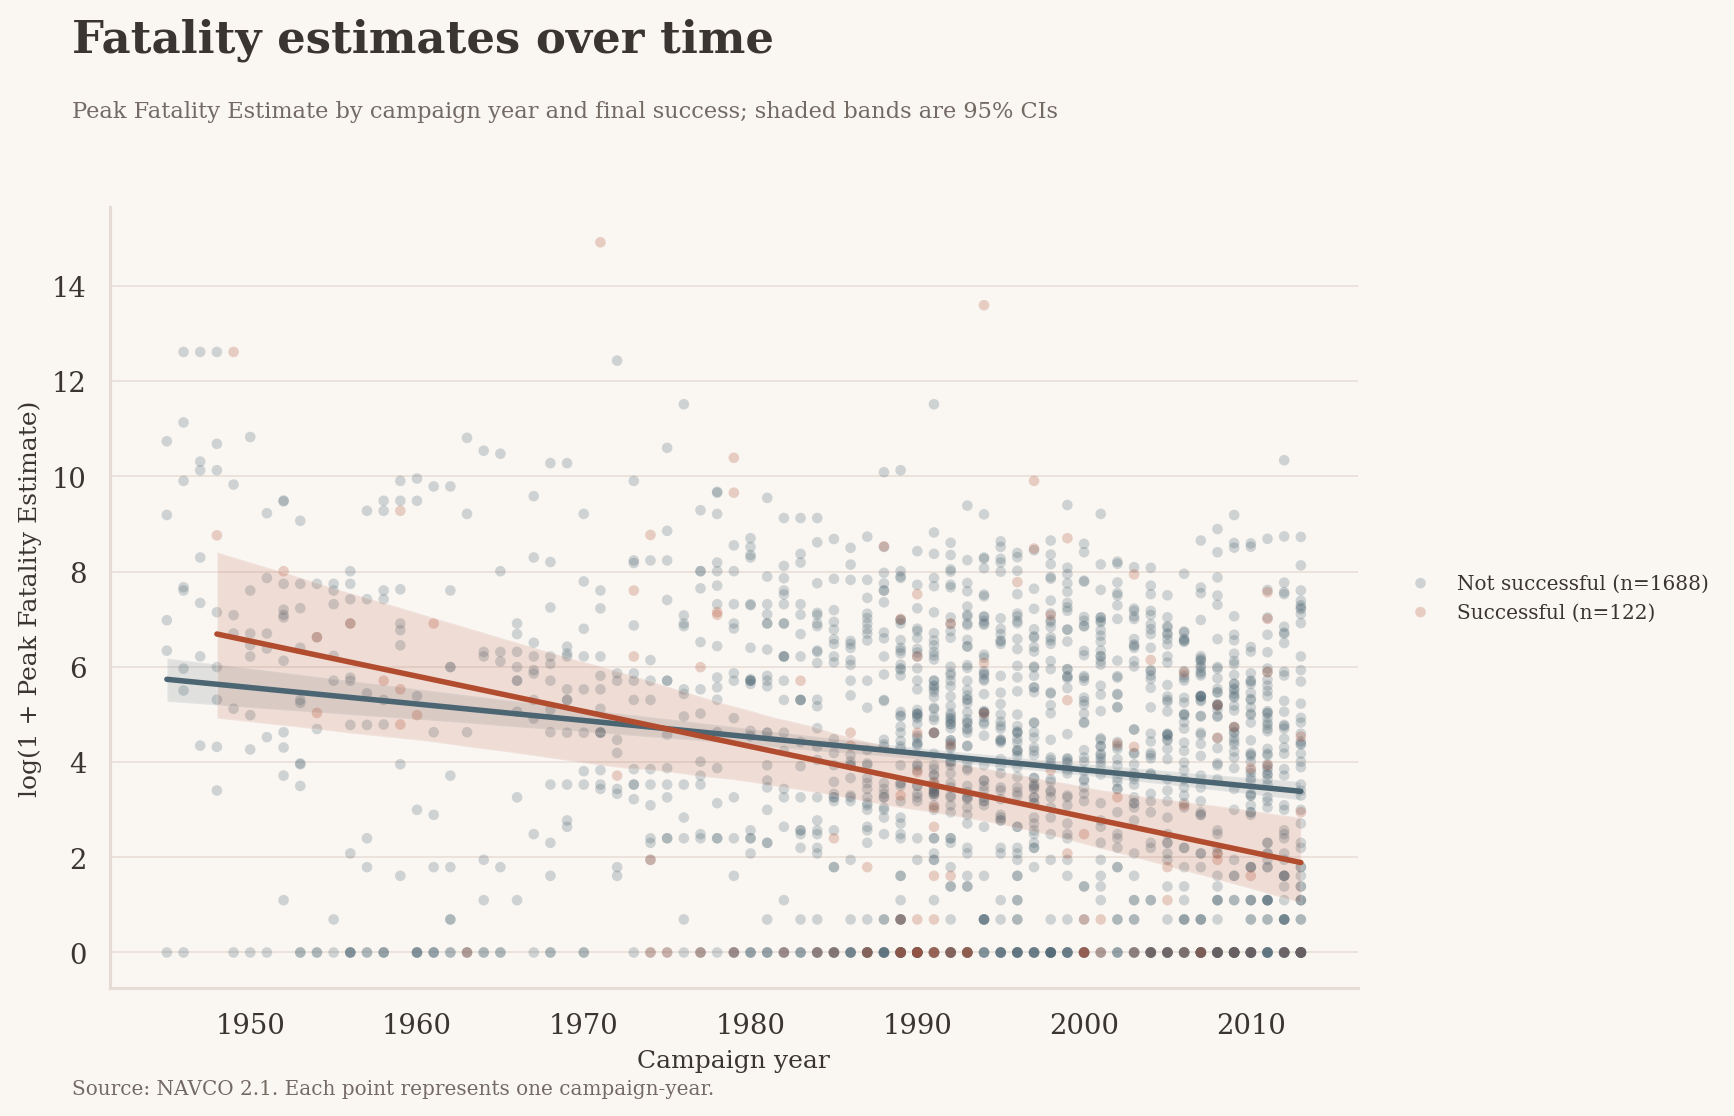

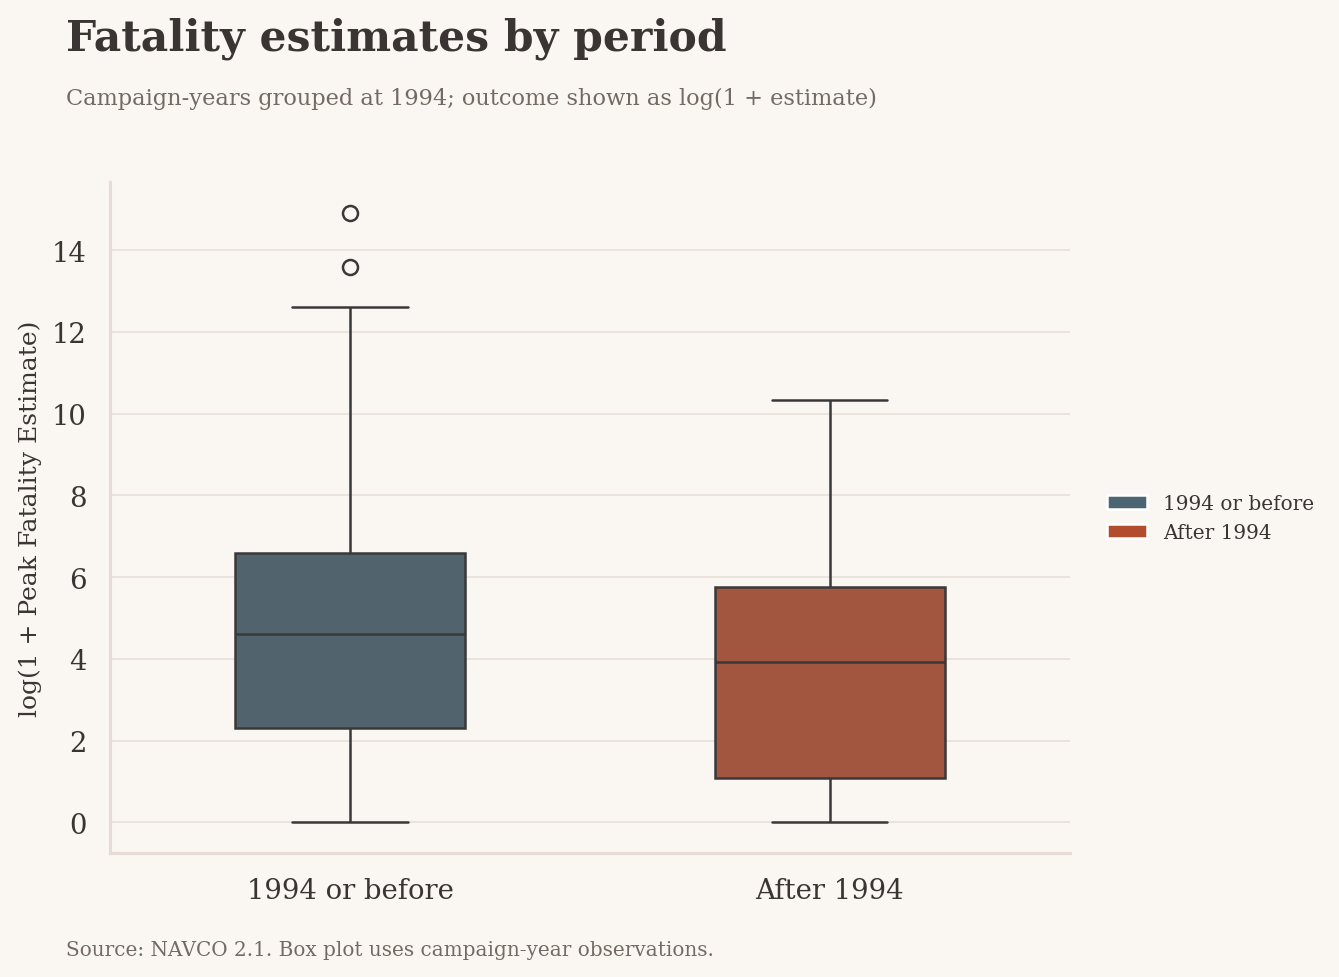

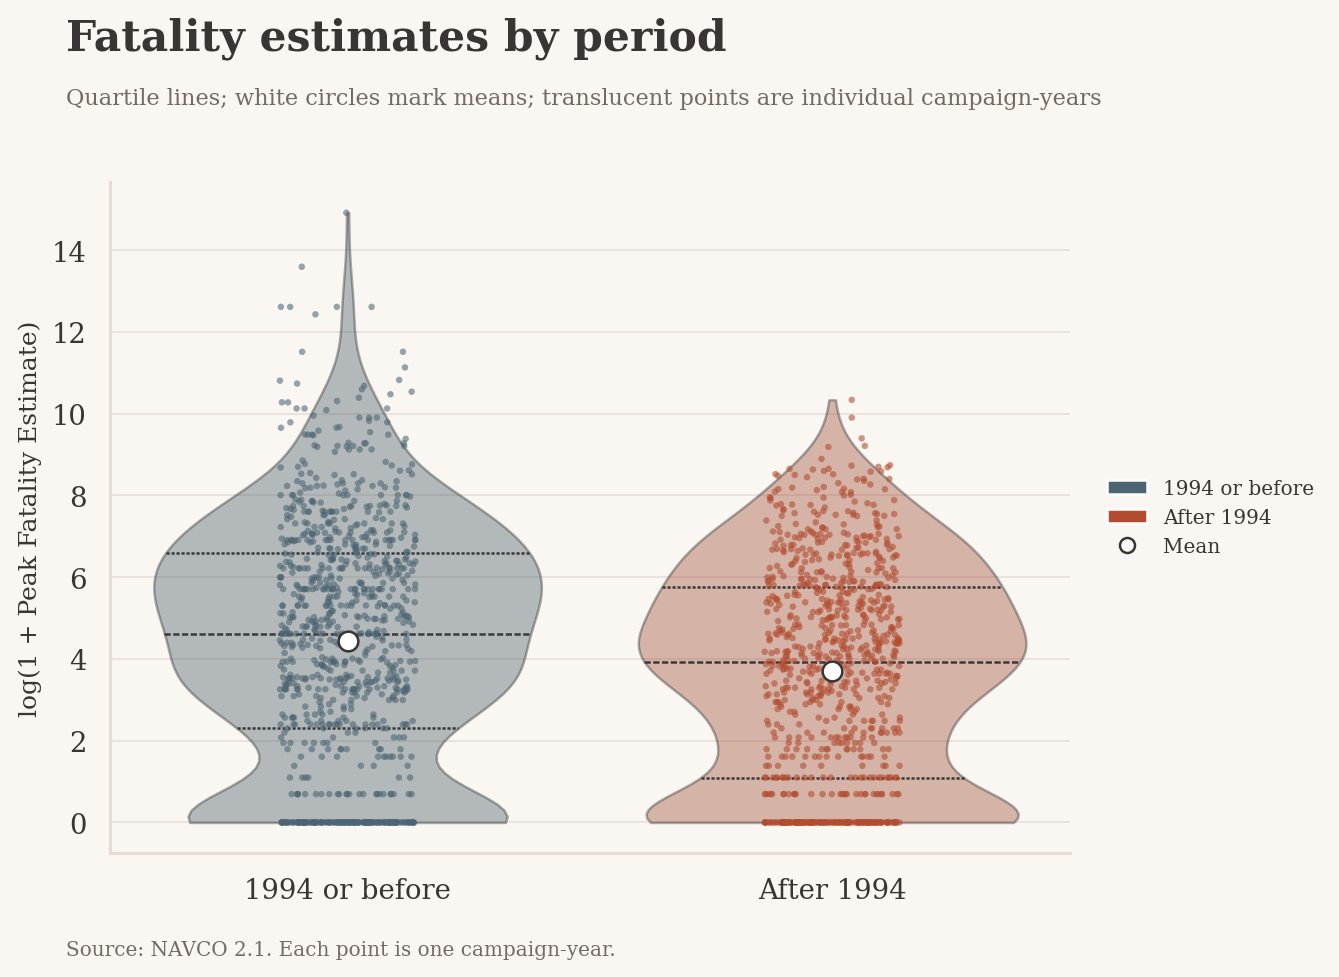

In [3]:
# Over-time graph and separate regressions with 95% confidence intervals.
time_data = df.dropna(subset=["year", "fatalities_high", "success"]).copy()
time_data["log_adjusted_fatalities"] = np.log1p(time_data["fatalities_high"])
time_data["Outcome"] = time_data["success"].map({0: "Not successful", 1: "Successful"})

fig, ax = plt.subplots(figsize=(10.5, 6.2))
for outcome, label, color in [(0, "Not successful", BLUE), (1, "Successful", RUST)]:
    subset = time_data.loc[time_data["success"] == outcome]
    ax.scatter(subset["year"], subset["log_adjusted_fatalities"], s=18,
               alpha=0.25, color=color, edgecolors="none", label=f"{label} (n={len(subset)})")
    sns.regplot(data=subset, x="year", y="log_adjusted_fatalities", scatter=False,
                ci=95, n_boot=500, color=color, line_kws={"linewidth": 2.2}, ax=ax)
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        subset["year"], subset["log_adjusted_fatalities"])
    print(f"{label}: slope={slope:.4f} log-points/year, R²={r_value**2:.4f}, p={p_value:.4g}")

fig.suptitle("Fatality estimates over time", x=0.08, y=0.99, ha="left", fontsize=18, fontweight="bold")
fig.text(0.08, 0.90, "Peak Fatality Estimate by campaign year and final success; shaded bands are 95% CIs",
         ha="left", color=MUTED, fontsize=9)
ax.set_xlabel("Campaign year")
ax.set_ylabel("log(1 + Peak Fatality Estimate)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
ax.grid(axis="x", visible=False)
fig.text(0.08, 0.025, "Source: NAVCO 2.1. Each point represents one campaign-year.", color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.10, right=0.76, bottom=0.12, top=0.82)
fig.savefig(FIGURE_DIR / "01_over_time.png", dpi=180, bbox_inches="tight", facecolor=PAPER)
plt.show()

# Compare raw fatalities by the requested year grouping and test the difference in means.
year_data = df.dropna(subset=["year", "fatalities_high"]).copy()
year_data["Period"] = np.where(year_data["year"] <= 1994, "1994 or before", "After 1994")
period_order = ["1994 or before", "After 1994"]
values_before = year_data.loc[year_data["Period"] == "1994 or before", "fatalities_high"]
values_after = year_data.loc[year_data["Period"] == "After 1994", "fatalities_high"]
avFatal_1994_and_before = values_before.mean()
avFatal_post_1994 = values_after.mean()
period_summary = year_data.groupby("Period")["fatalities_high"].agg(["count", "mean", "median", "std"]).reindex(period_order)
display(period_summary)
print(f"avFatal_1994_and_before = {avFatal_1994_and_before:,.3f}")
print(f"avFatal_post_1994 = {avFatal_post_1994:,.3f}")
print(f"Difference (before − after) = {avFatal_1994_and_before - avFatal_post_1994:,.3f}")
alpha = 0.05
welch_result = stats.ttest_ind(values_before, values_after, equal_var=False,
                               alternative="two-sided", nan_policy="omit")
print(f"Welch two-tailed test, H0: avFatal_1994_and_before − avFatal_post_1994 = 0; "
      f"t={welch_result.statistic:.4f}, df={welch_result.df:.2f}, p={welch_result.pvalue:.6g}, alpha={alpha}")
if welch_result.pvalue < alpha:
    print("Decision: reject H0 at alpha = 0.05.")
else:
    print("Decision: fail to reject H0 at alpha = 0.05.")

year_data["log_adjusted_fatalities"] = np.log1p(year_data["fatalities_high"])
fig, ax = plt.subplots(figsize=(8.2, 5.4))
sns.boxplot(data=year_data, x="Period", y="log_adjusted_fatalities", order=period_order,
            width=0.48, hue="Period", hue_order=period_order, palette=PERIOD_PALETTE,
            dodge=False, legend=False, linewidth=1.0, ax=ax)
year_box_legend = [Patch(facecolor=PERIOD_PALETTE[p], label=p) for p in period_order]
ax.legend(handles=year_box_legend, frameon=False, loc="center left",
          bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.suptitle("Fatality estimates by period", x=0.09, y=0.99, ha="left", fontsize=17, fontweight="bold")
fig.text(0.09, 0.90, "Campaign-years grouped at 1994; outcome shown as log(1 + estimate)",
         ha="left", color=MUTED, fontsize=9)
ax.set_xlabel("")
ax.set_ylabel("log(1 + Peak Fatality Estimate)")
ax.grid(axis="x", visible=False)
fig.text(0.09, 0.025, "Source: NAVCO 2.1. Box plot uses campaign-year observations.", color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.12, right=0.77, bottom=0.13, top=0.82)
fig.savefig(FIGURE_DIR / "02_year_boxplot.png", dpi=180, bbox_inches="tight", facecolor=PAPER)
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 5.4))
sns.violinplot(data=year_data, x="Period", y="log_adjusted_fatalities", order=period_order,
               hue="Period", hue_order=period_order, palette=PERIOD_PALETTE,
               dodge=False, legend=False, inner="quartile", cut=0, linewidth=1.0, ax=ax)
for violin_body in ax.collections:
    if isinstance(violin_body, PolyCollection):
        violin_body.set_alpha(0.42)
sns.stripplot(data=year_data, x="Period", y="log_adjusted_fatalities", order=period_order,
              hue="Period", hue_order=period_order, palette=PERIOD_PALETTE, dodge=False,
              alpha=0.58, size=2.6, jitter=0.14, legend=False, ax=ax)
year_violin_means = year_data.groupby("Period")["log_adjusted_fatalities"].mean().reindex(period_order)
ax.scatter([0, 1], year_violin_means.values, marker="o", s=62, facecolor="white",
           edgecolor=INK, linewidth=1.0, zorder=5, label="Mean")
fig.suptitle("Fatality estimates by period", x=0.09, y=0.99, ha="left", fontsize=17, fontweight="bold")
fig.text(0.09, 0.90, "Quartile lines; white circles mark means; translucent points are individual campaign-years",
         ha="left", color=MUTED, fontsize=9)
ax.set_xlabel("")
ax.set_ylabel("log(1 + Peak Fatality Estimate)")
ax.grid(axis="x", visible=False)
year_legend = [Patch(facecolor=PERIOD_PALETTE[p], label=p) for p in period_order]
year_legend.append(Line2D([0], [0], marker="o", linestyle="", markerfacecolor="white",
                          markeredgecolor=INK, label="Mean"))
ax.legend(handles=year_legend, frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.text(0.09, 0.025, "Source: NAVCO 2.1. Each point is one campaign-year.", color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.12, right=0.77, bottom=0.13, top=0.82)
fig.savefig(FIGURE_DIR / "03_year_violin.png", dpi=180, bbox_inches="tight", facecolor=PAPER)
plt.show()


## 4. Analysis by group and pairwise comparisons

**Requested prompt sections:** Campaign-ID-level ANOVAs at α = 0.05 for fatalities by flank response, violent-flank status, and campaign size; log-adjusted violin plots with quartiles, white-circle means, and translucent jittered points, descriptive labels, significance results and stars; a separate comparison of violent-flank codes 1 and 2; and all pairwise subgroup comparisons with the first-group mean, difference in means, two-tailed p-value, and Bonferroni-adjusted p-value, also printed as an image.

**Code explanation:** Annual fatality estimates are averaged within campaign ID. Each campaign is assigned its most frequent valid category for each grouping variable; ties use the smallest code. One-way ANOVAs compare campaign-level average fatalities. Pairwise two-sided Welch tests cover every observed category pair, with Bonferroni correction applied separately within each ANOVA family. The three primary violin plots and focused no-flank/violent-flank comparison plot use `log1p` outcomes, show quartiles and white-circle mean markers, and overlay translucent jittered campaign points. The full pairwise results are displayed as both a dataframe and a saved, displayed PNG table.

**Assumptions and star convention:** `-99` and blank category values are missing. The primary violent-flank analysis retains all codebook categories (0 = primarily violent campaign, 1 = no violent flank, 2 = violent flank); the focused figure includes only codes 1 and 2 as requested. A star annotates the omnibus ANOVA p-value: `*` p < .05, `**` p < .01, `***` p < .001, and `ns` p ≥ .05. Stars make the requested α = .05 decision legible; they do not convey effect size or causation. Classical ANOVA on skewed fatality averages has distributional limitations; pairwise tests use Welch’s unequal-variance version.

**Visual key:** Each subgroup keeps the same color across the plots. Legends sit to the right; white circles mark means, quartile lines appear inside violins, and individual campaign points are jittered and use 62% opacity over light 42%-opacity violin fills.


Flank response: F=4.737, p=0.00351974, **, alpha=0.05, campaigns=146
Violent-flank status: F=0.759, p=0.468882, ns, alpha=0.05, campaigns=348
Campaign size: F=1.311, p=0.258601, ns, alpha=0.05, campaigns=342
Pairwise Welch tests; Bonferroni correction is within each ANOVA family.


,Comparison,Mean fatalities (first group),Difference in means (first − second),Two-tailed p-value,Bonferroni-adjusted p-value
0,Flank response: No violent flank vs Nonviolent...,92.052128,-454.660025,0.098364,0.590187
1,Flank response: No violent flank vs Toleration...,92.052128,-2188.202393,0.114475,0.686851
2,Flank response: No violent flank vs Internal d...,92.052128,-1750.341713,0.295462,1.000000
3,Flank response: Nonviolent discipline vs Toler...,546.712153,-1733.542368,0.212611,1.000000
4,Flank response: Nonviolent discipline vs Inter...,546.712153,-1295.681688,0.437197,1.000000
5,Flank response: Toleration of violent flank vs...,2280.254521,437.860680,0.833305,1.000000
6,Violent-flank status: Primarily violent campai...,21713.261908,21647.086055,0.163523,0.490569
7,Violent-flank status: Primarily violent campai...,21713.261908,21504.239040,0.166308,0.498923
8,Violent-flank status: No violent flank vs Viol...,66.175853,-142.847015,0.039656,0.118967
9,"Campaign size: 1–999 vs 1,000–9,999",730.845540,-1661.323018,0.195646,1.000000


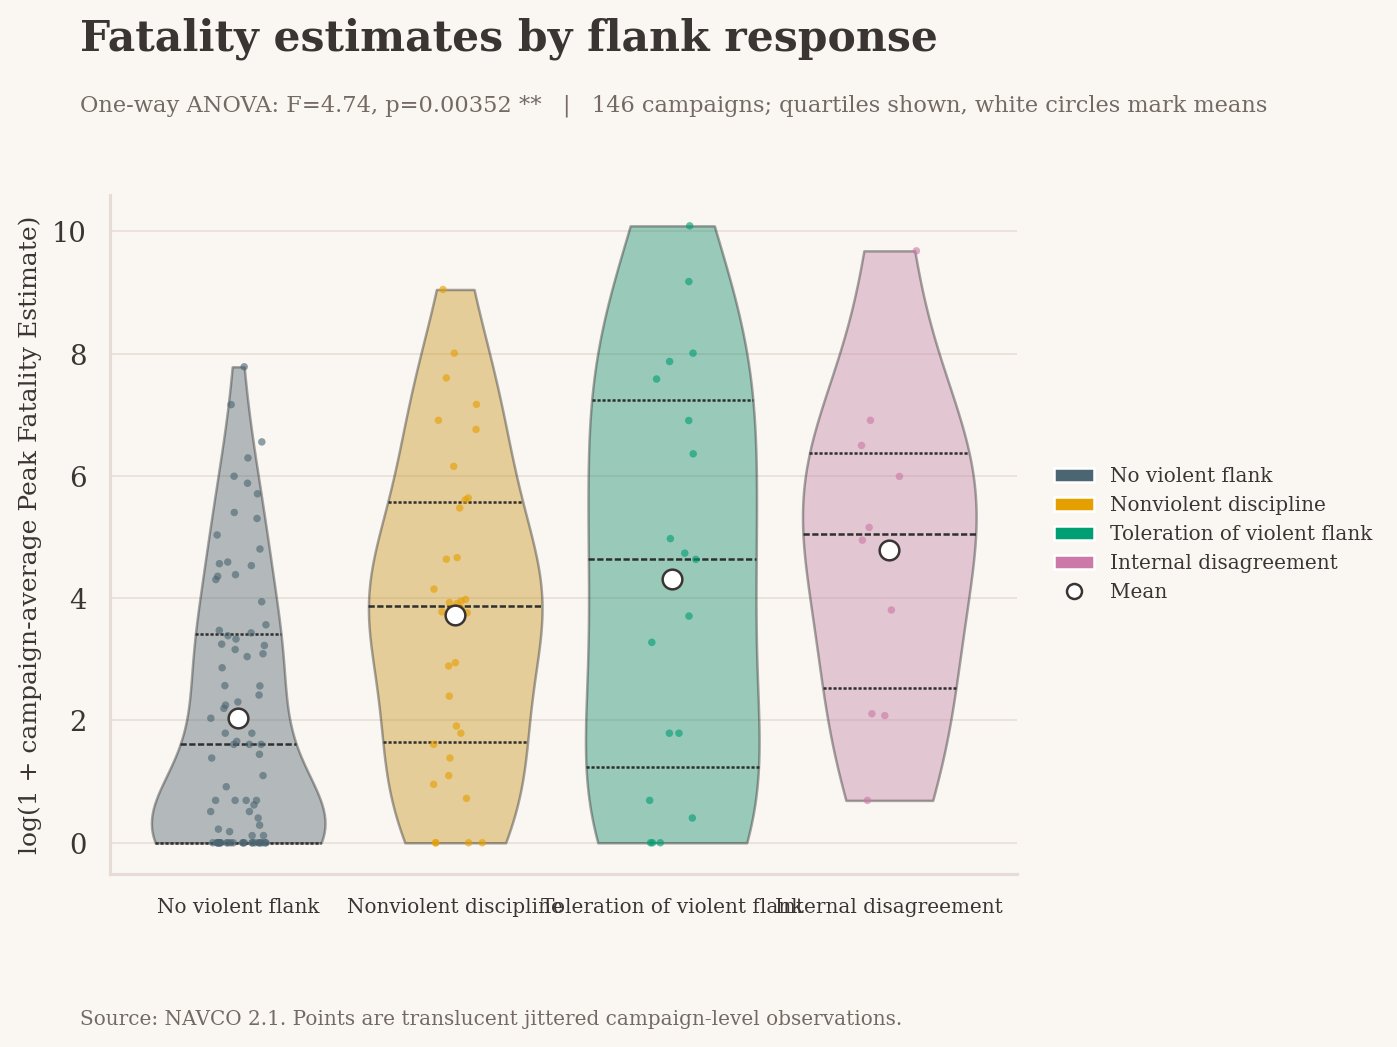

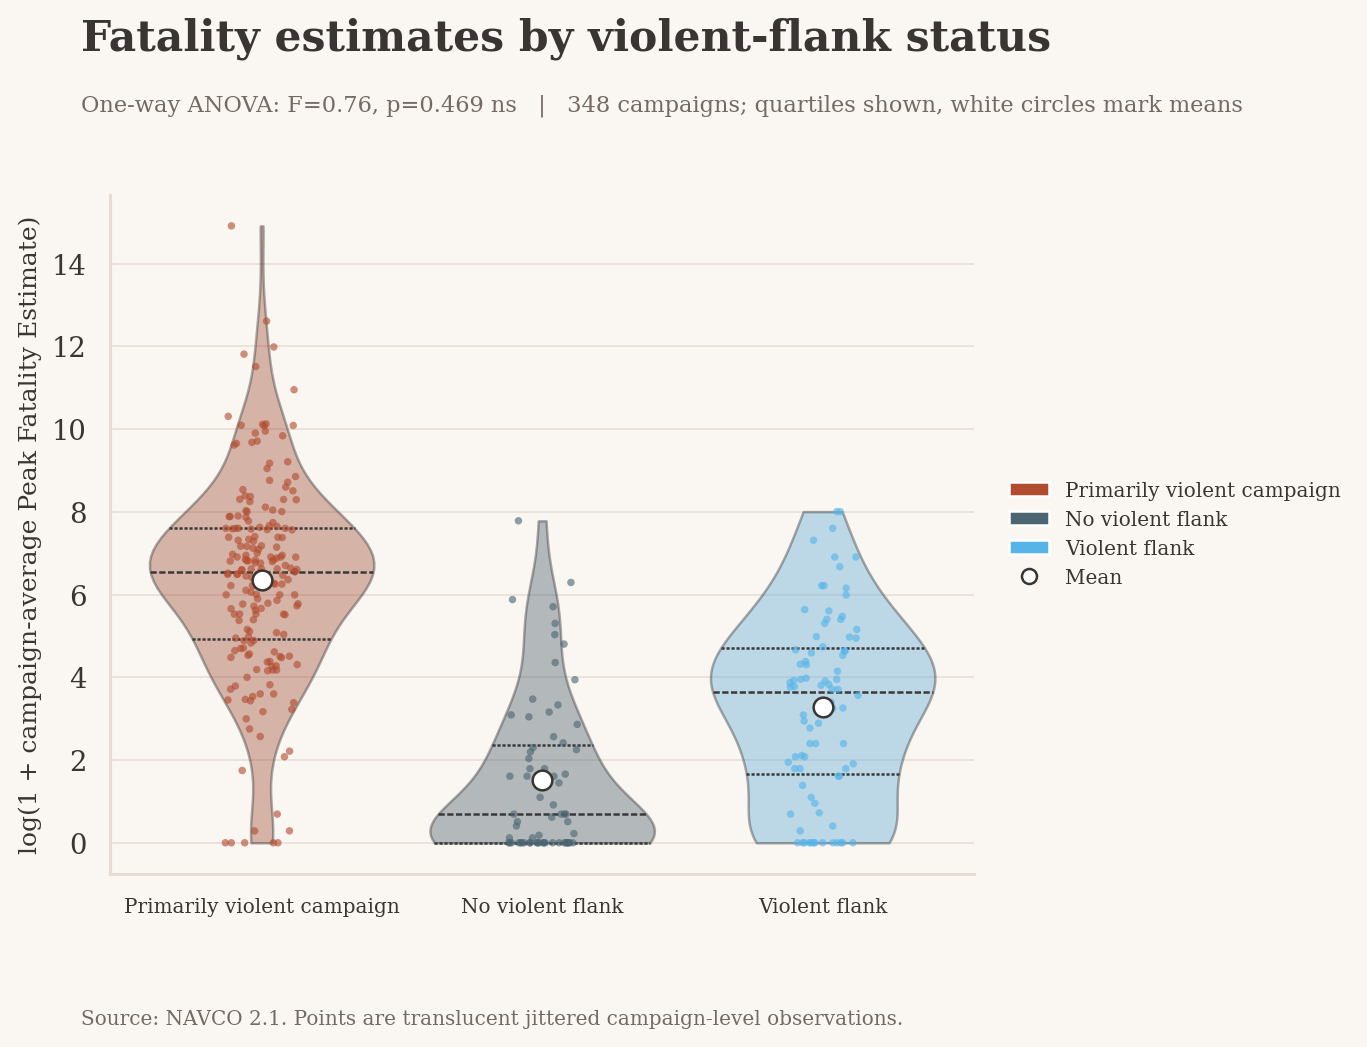

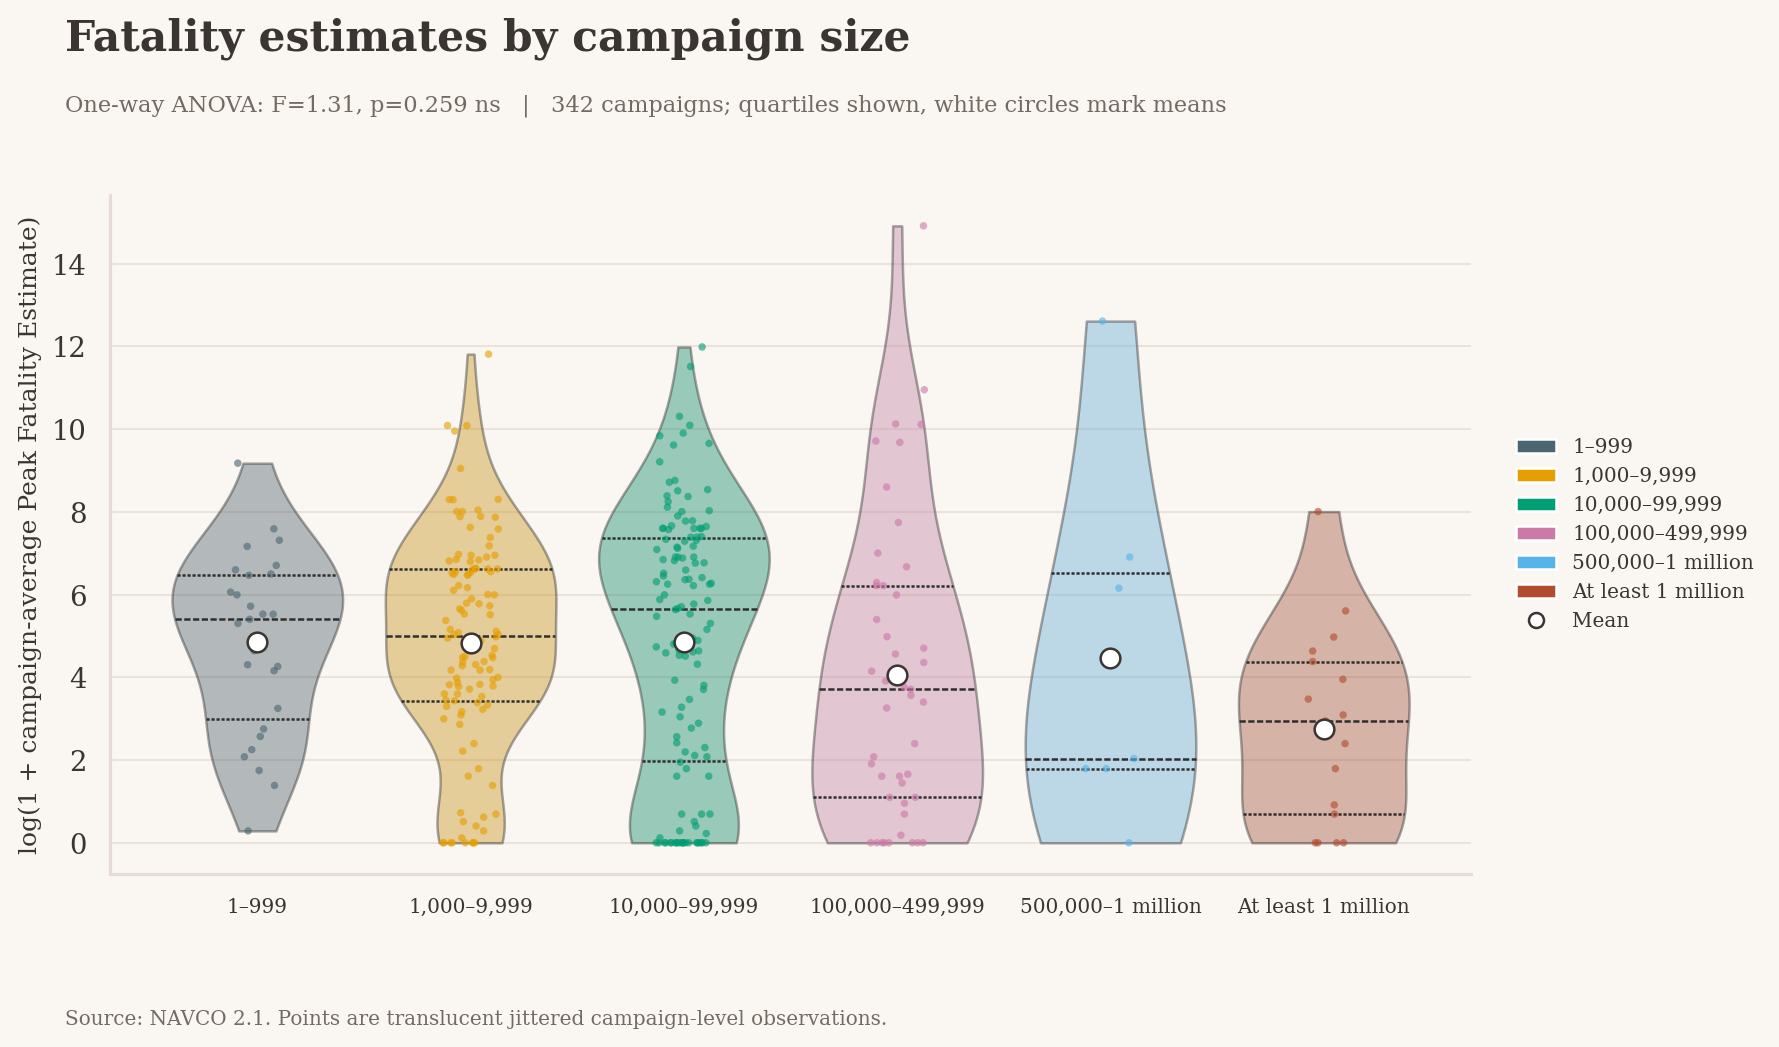

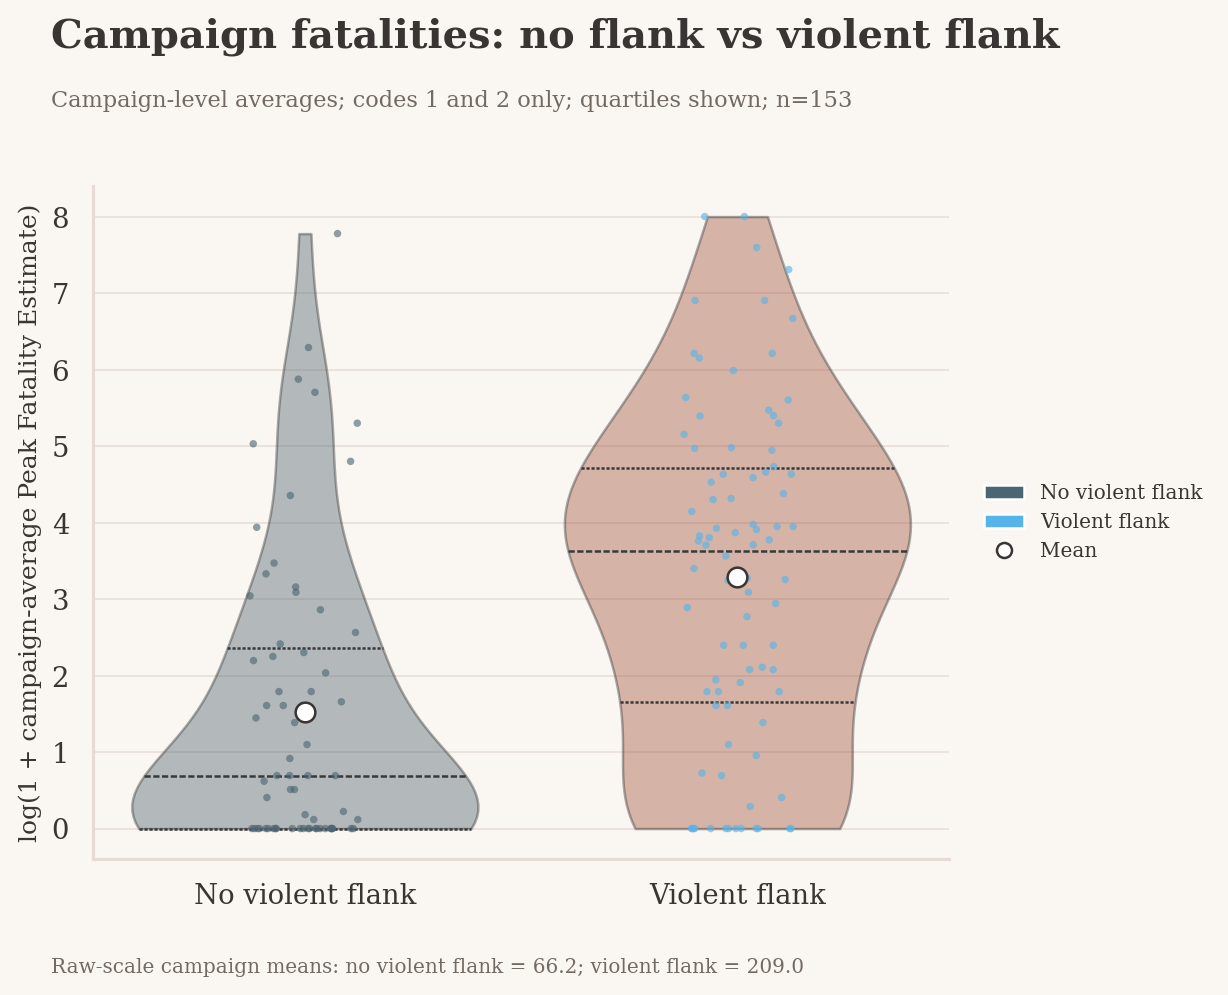

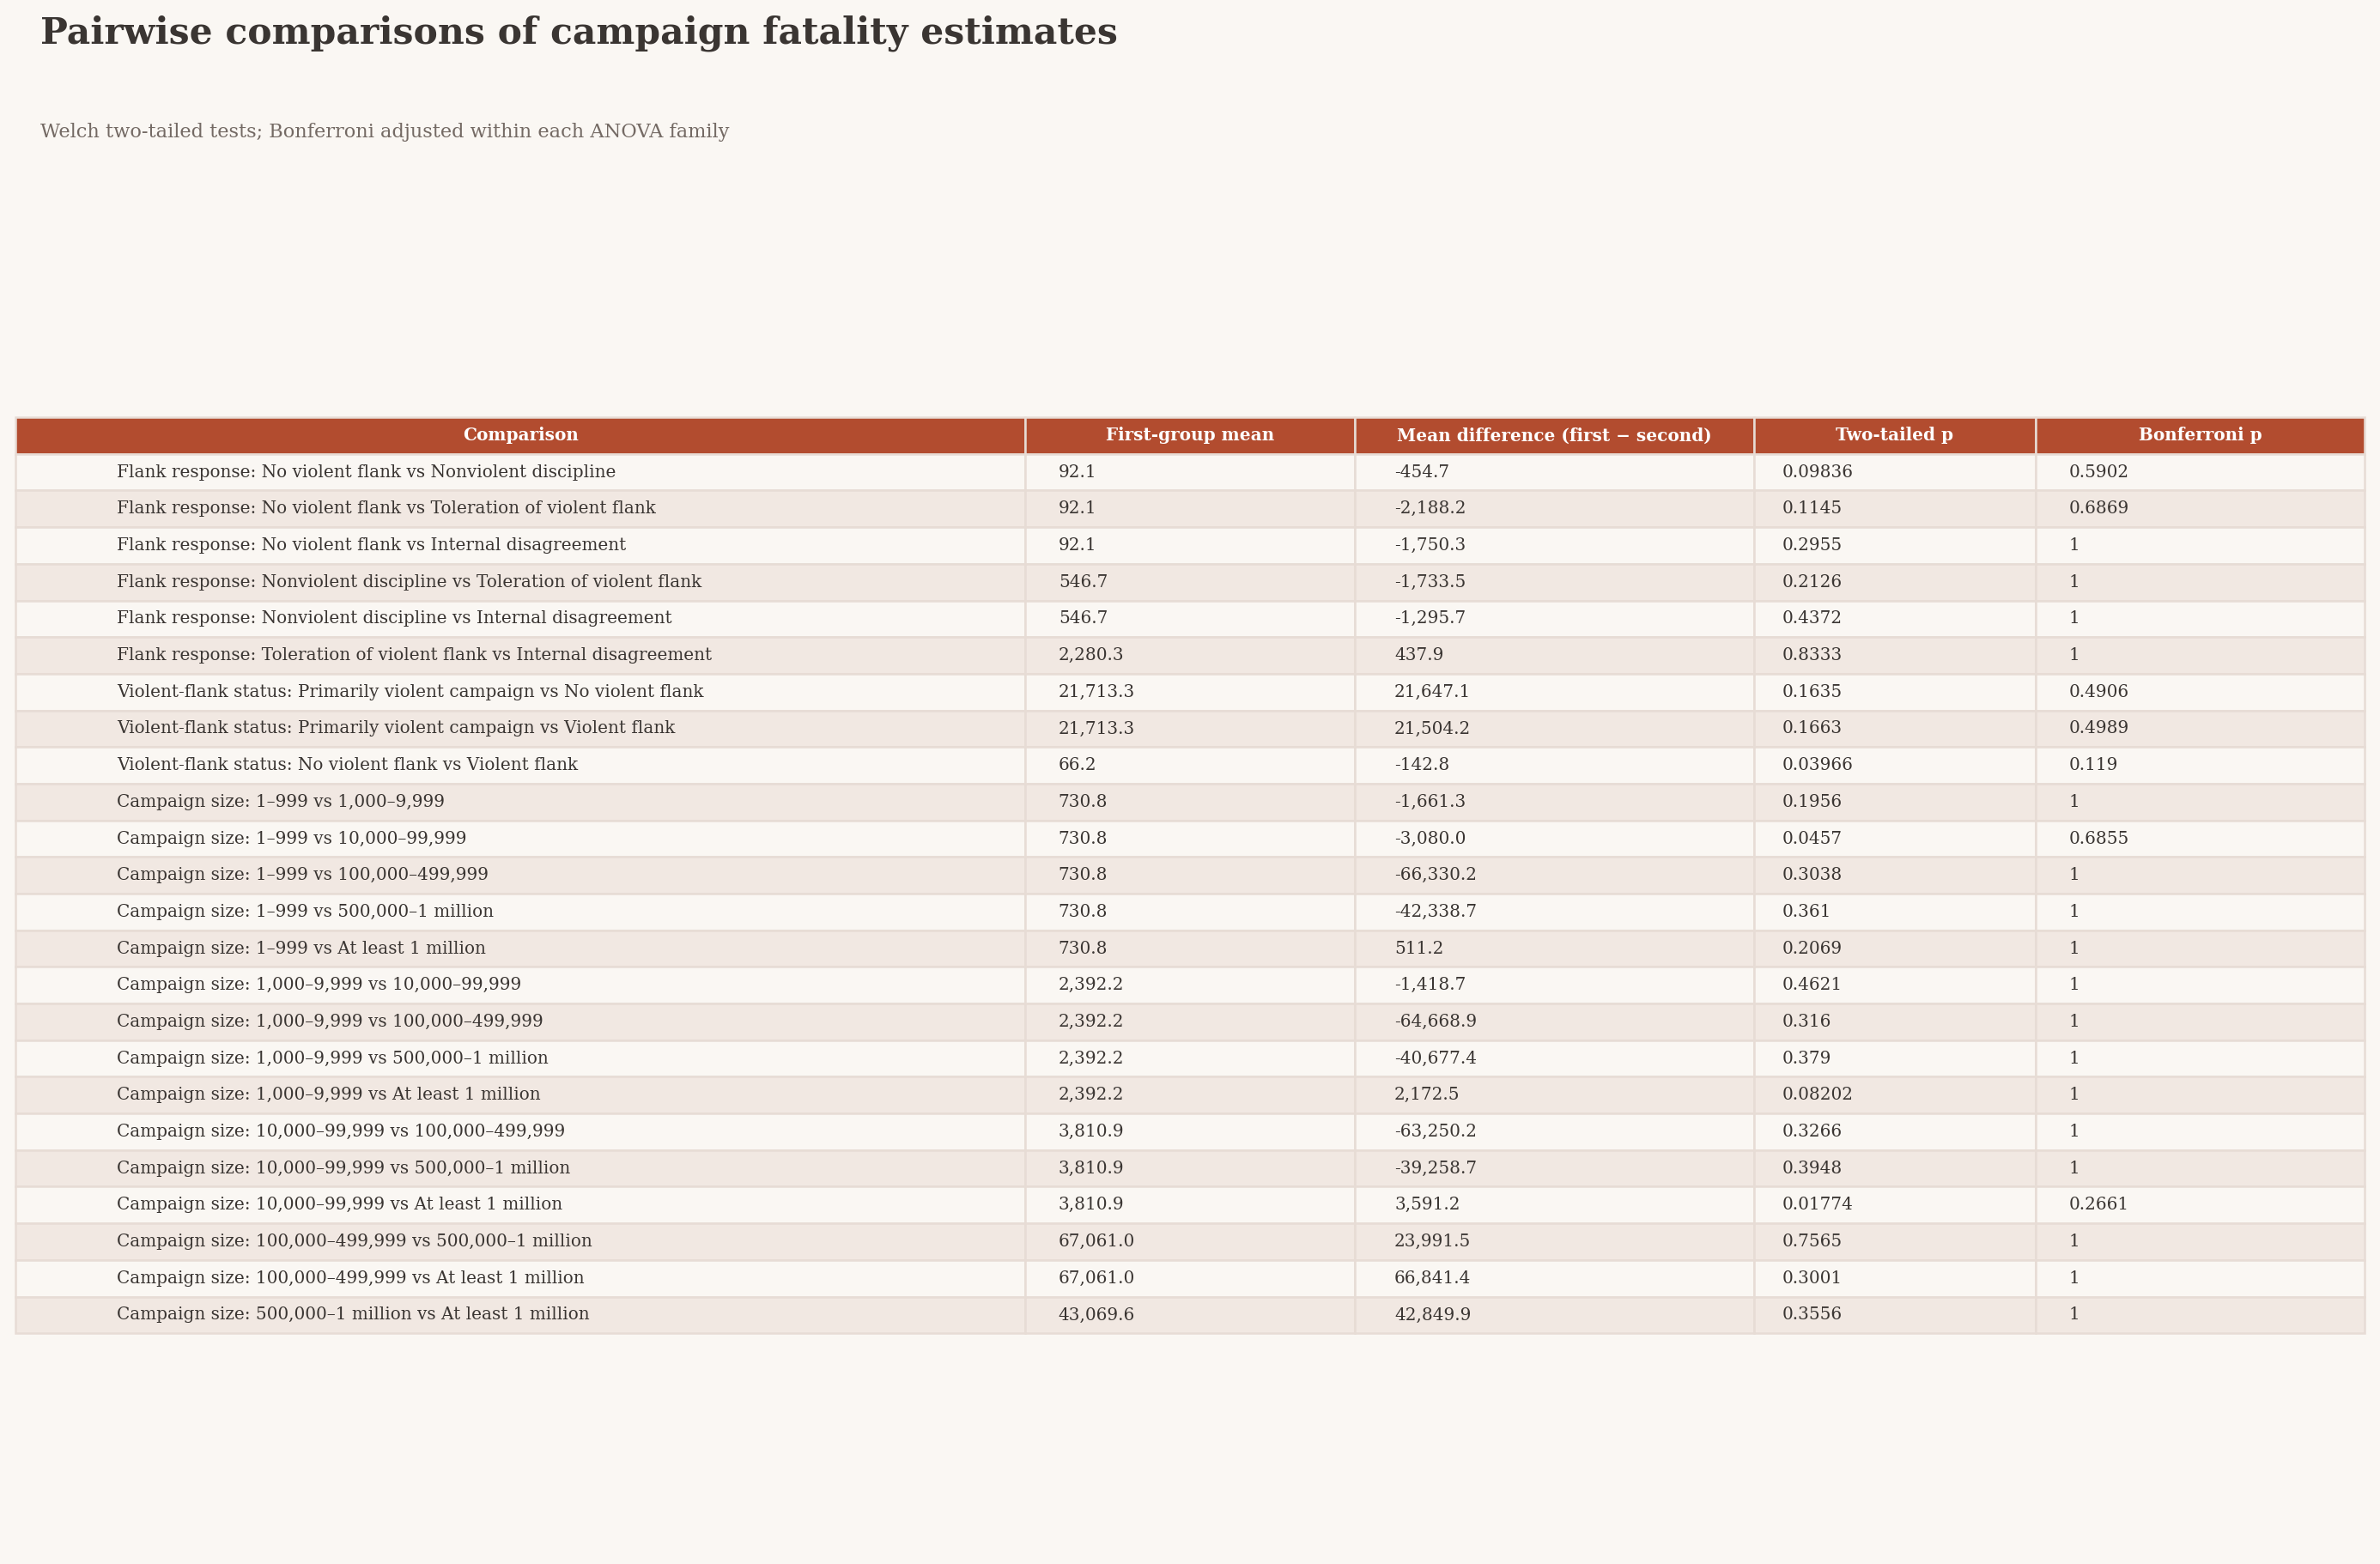

In [4]:
# One record per campaign: average observed annual fatalities and modal valid categories.
campaign_data = df.dropna(subset=["id", "fatalities_high"]).groupby("id", as_index=False).agg(
    fatalities_high=("fatalities_high", "mean")
)
for column in ["flank_response", "violent_flank", "camp_size"]:
    category_counts = (df.dropna(subset=["id", column])
                         .groupby(["id", column]).size()
                         .reset_index(name="year_count")
                         .sort_values(["id", "year_count", column], ascending=[True, False, True]))
    category_modes = category_counts.drop_duplicates("id").set_index("id")[column]
    campaign_data[column] = campaign_data["id"].map(category_modes)

category_specs = {
    "flank_response": {
        "title": "Fatality estimates by flank response",
        "short_title": "Flank response",
        "labels": {0: "No violent flank", 1: "Nonviolent discipline", 2: "Toleration of violent flank", 3: "Internal disagreement"}
    },
    "violent_flank": {
        "title": "Fatality estimates by violent-flank status",
        "short_title": "Violent-flank status",
        "labels": {0: "Primarily violent campaign", 1: "No violent flank", 2: "Violent flank"}
    },
    "camp_size": {
        "title": "Fatality estimates by campaign size",
        "short_title": "Campaign size",
        "labels": {0: "1–999", 1: "1,000–9,999", 2: "10,000–99,999",
                   3: "100,000–499,999", 4: "500,000–1 million", 5: "At least 1 million"}
    }
}

alpha = 0.05
anova_results = {}
pairwise_rows = []
for column, spec in category_specs.items():
    analysis = campaign_data.dropna(subset=[column, "fatalities_high"]).copy()
    analysis[column] = analysis[column].astype(int)
    observed_codes = sorted(analysis[column].unique())
    groups = [analysis.loc[analysis[column] == code, "fatalities_high"].to_numpy() for code in observed_codes]
    if len(groups) >= 2:
        anova_result = stats.f_oneway(*groups)
        anova_results[column] = anova_result
        if anova_result.pvalue < 0.001:
            significance = "***"
        elif anova_result.pvalue < 0.01:
            significance = "**"
        elif anova_result.pvalue < alpha:
            significance = "*"
        else:
            significance = "ns"
        print(f"{spec['short_title']}: F={anova_result.statistic:.3f}, "
              f"p={anova_result.pvalue:.6g}, {significance}, alpha={alpha}, campaigns={len(analysis)}")
        title_result = f"One-way ANOVA: F={anova_result.statistic:.2f}, p={anova_result.pvalue:.3g} {significance}"
    else:
        title_result = "ANOVA unavailable: fewer than two observed groups"
        print(f"{spec['short_title']}: {title_result}")

    # All pairwise category comparisons, with Bonferroni correction within this factor.
    family_rows = []
    for i, code_a in enumerate(observed_codes):
        values_a = analysis.loc[analysis[column] == code_a, "fatalities_high"]
        for code_b in observed_codes[i + 1:]:
            values_b = analysis.loc[analysis[column] == code_b, "fatalities_high"]
            pair_test = stats.ttest_ind(values_a, values_b, equal_var=False,
                                        alternative="two-sided", nan_policy="omit")
            label_a = spec["labels"].get(code_a, str(code_a))
            label_b = spec["labels"].get(code_b, str(code_b))
            family_rows.append({
                "Comparison": f"{spec['short_title']}: {label_a} vs {label_b}",
                "Mean fatalities (first group)": values_a.mean(),
                "Difference in means (first − second)": values_a.mean() - values_b.mean(),
                "Two-tailed p-value": pair_test.pvalue
            })
    number_of_family_tests = len(family_rows)
    for row in family_rows:
        row["Bonferroni-adjusted p-value"] = min(row["Two-tailed p-value"] * number_of_family_tests, 1.0)
        pairwise_rows.append(row)

    # Grouped violins show quartiles, white-circle means, and individual campaign values.
    analysis["log_adjusted_fatalities"] = np.log1p(analysis["fatalities_high"])
    analysis["Category"] = analysis[column].map(spec["labels"])
    plot_order = [spec["labels"].get(code, str(code)) for code in observed_codes]
    fig, ax = plt.subplots(figsize=(max(8, len(plot_order) * 2.1), 5.8))
    sns.violinplot(data=analysis, x="Category", y="log_adjusted_fatalities", order=plot_order,
                   hue="Category", hue_order=plot_order,
                   palette={label: LABEL_PALETTE[label] for label in plot_order},
                   dodge=False, legend=False, inner="quartile", cut=0, linewidth=1.0, ax=ax)
    for violin_body in ax.collections:
        if isinstance(violin_body, PolyCollection):
            violin_body.set_alpha(0.42)
    sns.stripplot(data=analysis, x="Category", y="log_adjusted_fatalities", order=plot_order,
                  hue="Category", hue_order=plot_order,
                  palette={label: LABEL_PALETTE[label] for label in plot_order}, dodge=False,
                  alpha=0.62, size=3.0, jitter=0.13, legend=False, ax=ax)
    category_means = analysis.groupby("Category")["log_adjusted_fatalities"].mean().reindex(plot_order)
    ax.scatter(np.arange(len(plot_order)), category_means.values, marker="o", s=62,
               facecolor="white", edgecolor=INK, linewidth=1.0, zorder=5, label="Mean")
    fig.suptitle(spec["title"], x=0.08, y=0.99, ha="left", fontsize=17, fontweight="bold")
    fig.text(0.08, 0.90, f"{title_result}   |   {len(analysis)} campaigns; quartiles shown, white circles mark means",
             ha="left", color=MUTED, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("log(1 + campaign-average Peak Fatality Estimate)")
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
    group_legend = [Patch(facecolor=LABEL_PALETTE[label], label=label) for label in plot_order]
    group_legend.append(Line2D([0], [0], marker="o", linestyle="", markerfacecolor="white",
                               markeredgecolor=INK, label="Mean"))
    ax.legend(handles=group_legend, frameon=False, loc="center left",
              bbox_to_anchor=(1.02, 0.5), fontsize=8)
    fig.text(0.08, 0.025, "Source: NAVCO 2.1. Points are translucent jittered campaign-level observations.", color=MUTED, fontsize=8)
    fig.subplots_adjust(left=0.10, right=0.70, bottom=0.17, top=0.82)
    fig.savefig(FIGURE_DIR / f"04_{column}_violin.png", dpi=180, bbox_inches="tight", facecolor=PAPER)
    plt.show()

# Focused comparison: campaigns whose modal code is 1 (no flank) or 2 (violent flank).
flank_focus = campaign_data.loc[campaign_data["violent_flank"].isin([1, 2])].copy()
flank_focus["Flank group"] = flank_focus["violent_flank"].map({1: "No violent flank", 2: "Violent flank"})
flank_focus["log_adjusted_fatalities"] = np.log1p(flank_focus["fatalities_high"])
focus_order = ["No violent flank", "Violent flank"]
focus_means = flank_focus.groupby("Flank group")["fatalities_high"].mean().reindex(focus_order)
fig, ax = plt.subplots(figsize=(7.8, 5.5))
sns.violinplot(data=flank_focus, x="Flank group", y="log_adjusted_fatalities", order=focus_order,
               hue="Flank group", hue_order=focus_order, dodge=False, legend=False,
               palette={focus_order[0]: BLUE, focus_order[1]: RUST},
               inner="quartile", cut=0, linewidth=1.0, ax=ax)
for violin_body in ax.collections:
    if isinstance(violin_body, PolyCollection):
        violin_body.set_alpha(0.42)
sns.stripplot(data=flank_focus, x="Flank group", y="log_adjusted_fatalities", order=focus_order,
              hue="Flank group", hue_order=focus_order,
              palette={label: LABEL_PALETTE[label] for label in focus_order}, dodge=False,
              alpha=0.62, size=3.0, jitter=0.13, legend=False, ax=ax)
focus_log_means = flank_focus.groupby("Flank group")["log_adjusted_fatalities"].mean().reindex(focus_order)
ax.scatter([0, 1], focus_log_means.values, marker="o", s=62, facecolor="white",
           edgecolor=INK, linewidth=1.0, zorder=5, label="Mean")
fig.suptitle("Campaign fatalities: no flank vs violent flank", x=0.09, y=0.99,
             ha="left", fontsize=16, fontweight="bold")
fig.text(0.09, 0.90, f"Campaign-level averages; codes 1 and 2 only; quartiles shown; n={len(flank_focus)}",
         ha="left", color=MUTED, fontsize=9)
ax.set_xlabel("")
ax.set_ylabel("log(1 + campaign-average Peak Fatality Estimate)")
ax.grid(axis="x", visible=False)
focus_legend = [Patch(facecolor=LABEL_PALETTE[label], label=label) for label in focus_order]
focus_legend.append(Line2D([0], [0], marker="o", linestyle="", markerfacecolor="white",
                           markeredgecolor=INK, label="Mean"))
ax.legend(handles=focus_legend, frameon=False, loc="center left",
          bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.text(0.09, 0.025, "Raw-scale campaign means: " +
         f"no violent flank = {focus_means.iloc[0]:,.1f}; violent flank = {focus_means.iloc[1]:,.1f}",
         color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.12, right=0.73, bottom=0.14, top=0.82)
fig.savefig(FIGURE_DIR / "05_no_violent_flank_vs_violent_flank.png", dpi=180,
            bbox_inches="tight", facecolor=PAPER)
plt.show()

# Full pairwise table, shown as dataframe and rendered image.
pairwise_table = pd.DataFrame(pairwise_rows, columns=[
    "Comparison", "Mean fatalities (first group)",
    "Difference in means (first − second)", "Two-tailed p-value",
    "Bonferroni-adjusted p-value"
])
print("Pairwise Welch tests; Bonferroni correction is within each ANOVA family.")
display(pairwise_table.round(6))

table_rows = []
for _, row in pairwise_table.iterrows():
    table_rows.append([
        row["Comparison"],
        f"{row['Mean fatalities (first group)']:,.1f}",
        f"{row['Difference in means (first − second)']:,.1f}",
        f"{row['Two-tailed p-value']:.4g}",
        f"{row['Bonferroni-adjusted p-value']:.4g}"
    ])
fig, ax = plt.subplots(figsize=(16, 10.5))
ax.axis("off")
fig.suptitle("Pairwise comparisons of campaign fatality estimates", x=0.04, y=0.985,
             ha="left", fontsize=17, fontweight="bold")
fig.text(0.04, 0.91, "Welch two-tailed tests; Bonferroni adjusted within each ANOVA family",
         ha="left", color=MUTED, fontsize=9)
table = ax.table(cellText=table_rows,
                 colLabels=["Comparison", "First-group mean", "Mean difference (first − second)",
                            "Two-tailed p", "Bonferroni p"],
                 colWidths=[0.43, 0.14, 0.17, 0.12, 0.14],
                 cellLoc="left", loc="center")
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.32)
for (row_index, column_index), cell in table.get_celld().items():
    cell.set_edgecolor(GRID)
    if row_index == 0:
        cell.set_facecolor(RUST)
        cell.set_text_props(color="white", weight="bold")
    elif row_index % 2 == 0:
        cell.set_facecolor("#F1E8E2")
        cell.set_text_props(color=INK)
    else:
        cell.set_facecolor(PAPER)
        cell.set_text_props(color=INK)
fig.subplots_adjust(left=0.03, right=0.98, top=0.87, bottom=0.04)
pairwise_image_path = FIGURE_DIR / "06_pairwise_comparisons.png"
fig.savefig(pairwise_image_path, dpi=180, bbox_inches="tight", facecolor=PAPER)
plt.show()
